# 09. Детекция и оценка покрытия

Модели из 07 и 08: детекция → кроп → «покрыта / не покрыта».
Выводятся уверенность и флаг сомнения. «Не покрыта» включает недостаточное покрытие.
Разметка покрытия предварительная; оценивается видимая окантовка.


In [1]:
from pathlib import Path
import hashlib
import json
import math
import os

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.ops import box_iou, nms

ROOT = Path.cwd().resolve()
if ROOT.name == 'research':
    ROOT = ROOT.parent
RUN = ROOT / 'models/recall90_20261024'
OUT = RUN / 'pipeline'
OUT.mkdir(parents=True, exist_ok=True)
DETECTOR_CONFIG = RUN / 'detection/selected_pipeline.json'
CLASSIFIER_CONFIG = RUN / 'coating/selected_pipeline.json'
IMAGE_PATH = ROOT / 'data_real/images/val/D01_001_300um.png'
EVAL_SPLIT = 'test'
RUN_EVALUATION = True
SHOW_UNCERTAINTY = True
BATCH = 32
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
os.environ['YOLO_CONFIG_DIR'] = str(RUN / 'detection/ultralytics')
from ultralytics import YOLO

detector_config = json.loads(DETECTOR_CONFIG.read_text(encoding='utf-8'))
classifier_config = json.loads(CLASSIFIER_CONFIG.read_text(encoding='utf-8'))
CLASSES = tuple(classifier_config['classes'])
RUSSIAN = classifier_config.get('russian_labels', {'coated': 'покрыта', 'insufficient_coating': 'не покрыта'})
SIZE = int(classifier_config['size'])
PADDING = float(classifier_config['padding'])
THRESHOLD = float(classifier_config['confidence_threshold'])
detector = YOLO(str(ROOT / detector_config['weights']), task='detect')
checkpoint = torch.load(ROOT / classifier_config['weights'], map_location='cpu', weights_only=True)
classifier = models.resnet18(weights=None)
classifier.fc = nn.Linear(classifier.fc.in_features, len(CLASSES))
classifier.load_state_dict(checkpoint['state_dict'])
classifier = classifier.to(DEVICE).eval()
print('Детектор:', detector_config.get('variant', detector_config['weights']))
print('Классификатор:', classifier_config['profile'], '| метки:', classifier_config['label_origin'])

Детектор: detail1280_light_clahe_tiles768
Классификатор: mild_aug | метки: provisional_assistant_visual


## Модели и предобработка

Детектор использует выбранные тайлы, предобработку и порог.
Классификатор получает исходный кроп с контекстом и применяет свою предобработку.


In [2]:
def letterbox(image, size):
    image = image.convert('RGB')
    array = np.asarray(image)
    border = np.concatenate((array[0], array[-1], array[:, 0], array[:, -1]))
    color = tuple(np.median(border, axis=0).astype(int))
    return ImageOps.pad(image, (size, size), method=Image.Resampling.BICUBIC, color=color)


def prepare_crop(image, preprocessing='raw'):
    image = image.convert('RGB')
    if preprocessing == 'clahe':
        gray = cv2.cvtColor(np.asarray(image), cv2.COLOR_RGB2GRAY)
        gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
        image = Image.fromarray(gray).convert('RGB')
    return image


TENSOR = transforms.Compose([transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])


def classification_scores(predictions):
    matrix = np.zeros((2, 2), dtype=int)
    for target, predicted in predictions[['target', 'predicted']].itertuples(index=False, name=None):
        if target in (0, 1):
            matrix[int(target), int(predicted)] += 1
    tp, support = np.diag(matrix), matrix.sum(1)
    precision = np.divide(tp, matrix.sum(0), out=np.zeros(2, dtype=float), where=matrix.sum(0) > 0)
    recall = np.divide(tp, support, out=np.full(2, np.nan), where=support > 0)
    f1 = np.divide(2 * tp, support + matrix.sum(0), out=np.zeros(2, dtype=float),
                   where=support + matrix.sum(0) > 0)
    scores = dict(count=int(matrix.sum()), accuracy=float(tp.sum() / max(matrix.sum(), 1)),
        balanced_accuracy=float(np.nanmean(recall)) if support.any() else None,
        macro_f1=float(f1.mean()), support_coated=int(support[0]), support_insufficient=int(support[1]))
    return scores, matrix, precision, recall


def tile_starts(length, size, overlap):
    if length <= size:
        return [0]
    step = max(1, round(size * (1 - overlap)))
    return sorted(set([*range(0, length - size + 1, step), length - size]))


def detect_particles(source):
    config = detector_config
    image = source.convert('RGB')
    if config.get('preprocessing', 'raw') == 'clahe':
        gray = np.asarray(source.convert('L'))
        gray = cv2.createCLAHE(clipLimit=float(config.get('clahe_clip', 2.0)),
            tileGridSize=tuple(config.get('clahe_grid', (8, 8)))).apply(gray)
        image = Image.fromarray(gray).convert('RGB')
    width, height = source.size

    def raw(patch):
        result = detector.predict(patch, imgsz=config['imgsz'], conf=config.get('ap_conf', 0.001),
            iou=0.7, max_det=config.get('max_det', 1000), device=0 if DEVICE.type == 'cuda' else 'cpu',
            verbose=False, rect=True, half=False, save=False)[0]
        return torch.cat((result.boxes.xyxy.cpu(), result.boxes.conf.cpu()[:, None]), 1)

    parts = [raw(image)]
    size = config.get('tile_size')
    if size:
        for y in tile_starts(height, size, config.get('overlap', 0.25)):
            for x in tile_starts(width, size, config.get('overlap', 0.25)):
                x2, y2 = min(width, x + size), min(height, y + size)
                boxes = raw(image.crop((x, y, x2, y2)))
                complete = torch.ones(len(boxes), dtype=torch.bool)
                if x > 0:
                    complete &= boxes[:, 0] > 3
                if y > 0:
                    complete &= boxes[:, 1] > 3
                if x2 < width:
                    complete &= boxes[:, 2] < x2 - x - 3
                if y2 < height:
                    complete &= boxes[:, 3] < y2 - y - 3
                boxes = boxes[complete]
                boxes[:, :4] += torch.tensor([x, y, x, y])
                parts.append(boxes)
    boxes = torch.cat(parts)
    if len(boxes):
        boxes = boxes[nms(boxes[:, :4], boxes[:, 4], config.get('merge_iou', 0.5))[:config.get('max_det', 1000)]]
        boxes = boxes[boxes[:, 4] >= config['confidence']]
    return boxes.numpy()


def padded_crop(source, box):
    x1, y1, x2, y2 = map(float, box[:4])
    dx, dy = (x2 - x1) * PADDING, (y2 - y1) * PADDING
    bounds = (max(0, math.floor(x1 - dx)), max(0, math.floor(y1 - dy)),
              min(source.width, math.ceil(x2 + dx)), min(source.height, math.ceil(y2 + dy)))
    return source.crop(bounds)


@torch.inference_mode()
def classify_images(images):
    probabilities = []
    for begin in range(0, len(images), BATCH):
        batch = [TENSOR(letterbox(prepare_crop(image, classifier_config['preprocessing']), SIZE))
                 for image in images[begin:begin + BATCH]]
        probabilities.append(classifier(torch.stack(batch).to(DEVICE)).softmax(1).cpu().numpy())
    return np.concatenate(probabilities) if probabilities else np.empty((0, len(CLASSES)))


def predict_image(image_path):
    source = Image.open(image_path).convert('RGB')
    boxes = detect_particles(source)
    crops = [padded_crop(source, box) for box in boxes]
    probabilities = classify_images(crops)
    rows = []
    for index, (box, prob) in enumerate(zip(boxes, probabilities)):
        label = CLASSES[int(prob.argmax())]
        confidence = float(prob.max())
        rows.append(dict(detection_index=index, source=str(Path(image_path).resolve()),
            x1=float(box[0]), y1=float(box[1]), x2=float(box[2]), y2=float(box[3]),
            detector_confidence=float(box[4]), prediction=label, prediction_ru=RUSSIAN[label],
            class_confidence=confidence, p_coated=float(prob[CLASSES.index('coated')]),
            p_insufficient=float(prob[CLASSES.index('insufficient_coating')]), uncertain_flag=confidence < THRESHOLD,
            status='needs_review' if confidence < THRESHOLD else 'automatic_hypothesis'))
    columns = ['detection_index', 'source', 'x1', 'y1', 'x2', 'y2', 'detector_confidence',
               'prediction', 'prediction_ru', 'class_confidence', 'p_coated', 'p_insufficient', 'uncertain_flag', 'status']
    return source, pd.DataFrame(rows, columns=columns), crops

## Предсказания

Путь к снимку — `IMAGE_PATH`. Зелёный — «покрыта», красный — «не покрыта», `?` — низкая уверенность.
На плотных кадрах показаны номера; классы и уверенность доступны в галерее и CSV.


,detection_index,prediction_ru,class_confidence,detector_confidence,uncertain_flag
0,0,не покрыта,0.971,0.931,False
1,1,не покрыта,0.778,0.925,False
2,2,покрыта,0.989,0.919,False
3,3,не покрыта,0.974,0.919,False
4,4,покрыта,0.668,0.919,False
...,...,...,...,...,...
91,91,покрыта,0.737,0.475,False
92,92,не покрыта,0.993,0.449,False
93,93,покрыта,0.987,0.443,False
94,94,не покрыта,0.936,0.432,False


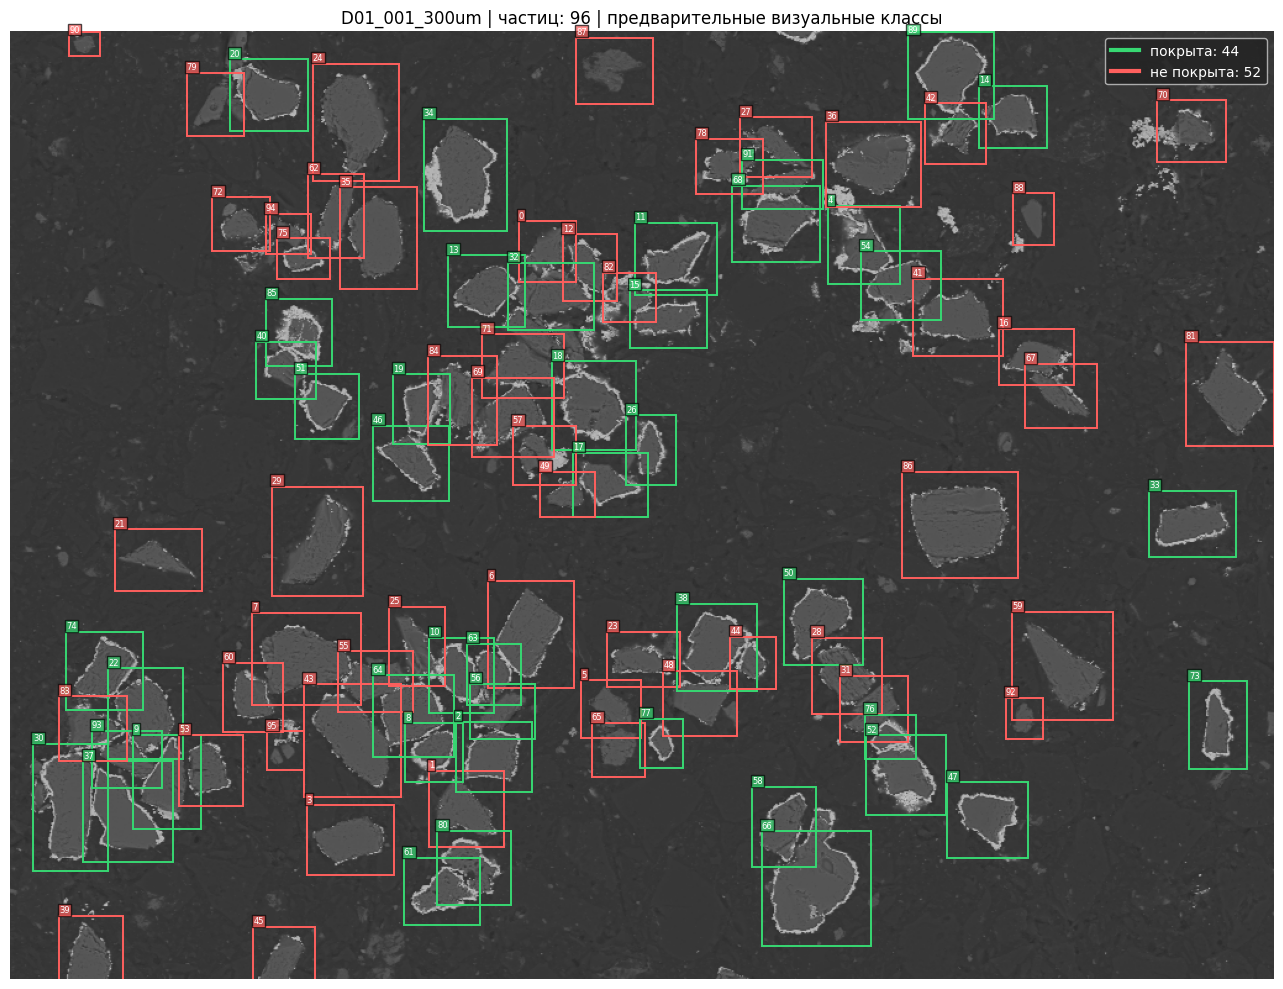

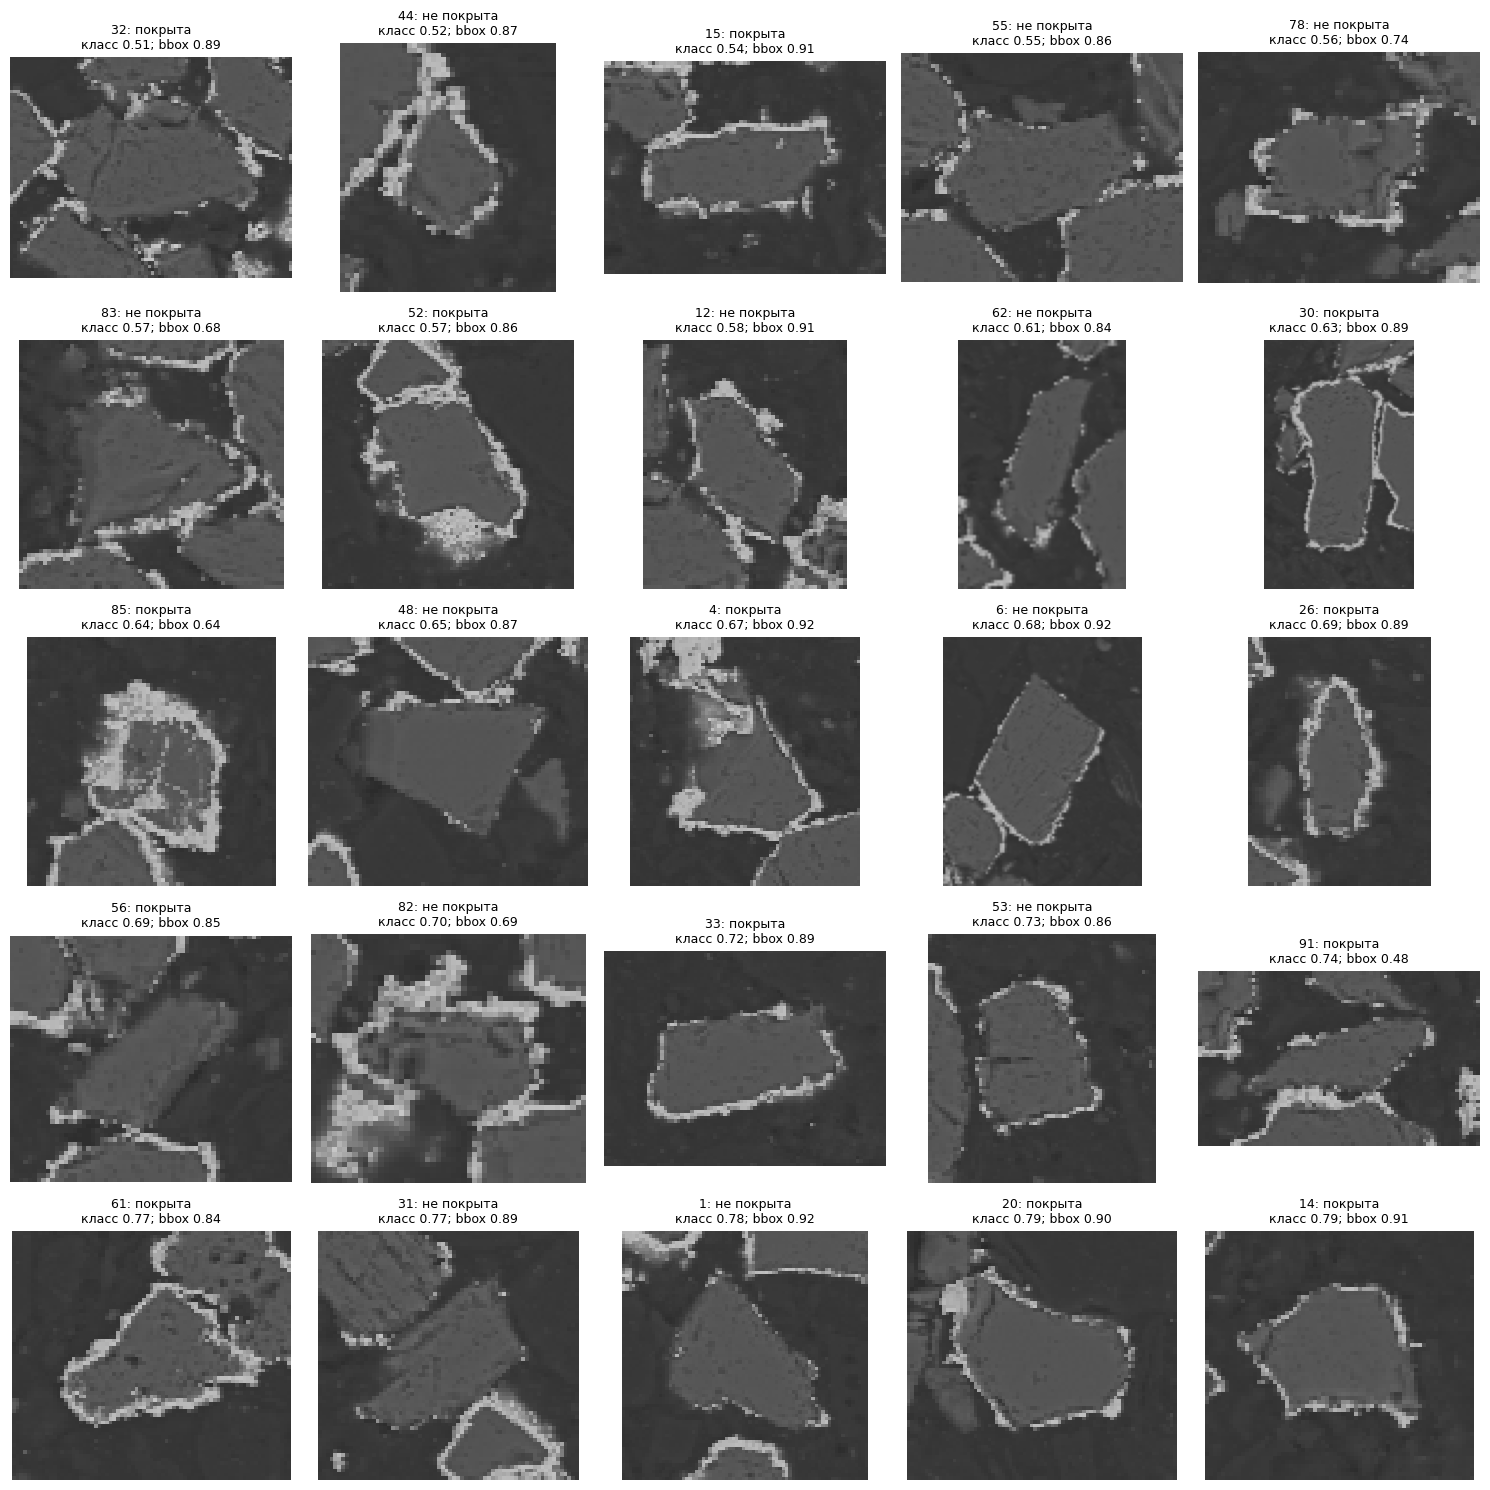

In [3]:
source, result, crops = predict_image(IMAGE_PATH)
display(result[['detection_index', 'prediction_ru', 'class_confidence', 'detector_confidence', 'uncertain_flag']].round(3))
result.to_csv(OUT / f'{IMAGE_PATH.stem}_predictions.csv', index=False)
fig, ax = plt.subplots(figsize=(15, 10))
ax.imshow(source)
dense = len(result) > 30
for row in result.itertuples(index=False):
    color = '#37d872' if row.prediction == 'coated' else '#ff605e'
    flag = ' ?' if SHOW_UNCERTAINTY and row.uncertain_flag else ''
    ax.add_patch(plt.Rectangle((row.x1, row.y1), row.x2 - row.x1, row.y2 - row.y1,
                               fill=False, edgecolor=color, linewidth=1.4))
    caption = str(row.detection_index) if dense else f'{row.detection_index}: {row.prediction_ru} {row.class_confidence:.2f}{flag}'
    ax.text(row.x1, max(0, row.y1 - 3), caption, fontsize=6 if dense else 8,
            color='white', bbox=dict(facecolor=color, alpha=0.7, pad=1))
counts = result.prediction.value_counts()
ax.legend(handles=[Line2D([], [], color='#37d872', linewidth=3,
                         label=f"покрыта: {counts.get('coated', 0)}"),
                   Line2D([], [], color='#ff605e', linewidth=3,
                         label=f"не покрыта: {counts.get('insufficient_coating', 0)}")],
          loc='upper right', facecolor='#222222', labelcolor='white', fontsize=10)
ax.set_title(f'{IMAGE_PATH.stem} | частиц: {len(result)} | предварительные визуальные классы')
ax.axis('off')
plt.tight_layout()
fig.savefig(OUT / f'{IMAGE_PATH.stem}_overlay.jpg', dpi=160, bbox_inches='tight')
plt.show()

gallery = result.sort_values('class_confidence').head(25)
if len(gallery):
    fig, axes = plt.subplots(math.ceil(len(gallery) / 5), 5,
        figsize=(15, 3 * math.ceil(len(gallery) / 5)), squeeze=False)
    for ax, row in zip(axes.flat, gallery.itertuples(index=False)):
        ax.imshow(crops[row.detection_index])
        flag = '\nсомнительно' if SHOW_UNCERTAINTY and row.uncertain_flag else ''
        ax.set_title(f'{row.detection_index}: {row.prediction_ru}\nкласс {row.class_confidence:.2f}; bbox {row.detector_confidence:.2f}{flag}', fontsize=9)
        ax.axis('off')
    for ax in list(axes.flat)[len(gallery):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## Метрики моделей и пайплайна

Детекция: все размеченные bbox, сопоставление при IoU ≥0.50.
Классификация: кропы с бинарными метками покрытия.
Пайплайн: доля одновременно найденных и верно классифицированных частиц с учётом пропусков.
Спорные и неразмеченные классы не оцениваются. Параметры по test не меняются.


In [4]:
manifest = pd.read_csv(ROOT / classifier_config['manifest'], keep_default_na=False)
labels = pd.read_csv(ROOT / classifier_config['labels'], dtype=str, keep_default_na=False)
table = manifest.merge(labels[['crop_id', 'label', 'reviewer', 'note']], on='crop_id', how='left', validate='one_to_one')
table[['label', 'reviewer', 'note']] = table[['label', 'reviewer', 'note']].fillna('')
if hashlib.sha256((ROOT / classifier_config['labels']).read_bytes()).hexdigest() != classifier_config['labels_sha256']:
    print('Метки изменились после выбора модели; отчёт относится к текущей таблице, независимость не гарантируется.')


def evaluate_gt_crops(split):
    rows = table.loc[(table.split == split) & table.label.isin(CLASSES)].reset_index(drop=True)
    predictions = []
    for begin in range(0, len(rows), BATCH):
        batch = rows.iloc[begin:begin + BATCH]
        images = [Image.open(ROOT / row['crop']).convert('RGB') for _, row in batch.iterrows()]
        for (_, row), prob in zip(batch.iterrows(), classify_images(images)):
            predictions.append(dict(crop_id=row.crop_id, image_id=row.image_id,
                target=CLASSES.index(row.label), predicted=int(prob.argmax()), confidence=float(prob.max())))
    prediction = pd.DataFrame(predictions, columns=['crop_id', 'image_id', 'target', 'predicted', 'confidence'])
    prediction['uncertain_flag'] = prediction.confidence < THRESHOLD
    prediction.to_csv(OUT / f'{split}_classifier_gt.csv', index=False)
    metrics, matrix, _, _ = classification_scores(prediction)
    accepted = prediction.loc[~prediction.uncertain_flag]
    metrics.update(coverage=len(accepted) / max(len(prediction), 1),
        accepted_accuracy=float((accepted.target == accepted.predicted).mean()) if len(accepted) else None)
    return metrics, matrix


def evaluate_pipeline(split):
    frames, matches = [], []
    for image_id, gt in table.loc[table.split == split].groupby('image_id'):
        gt = gt.reset_index(drop=True)
        _, predicted, _ = predict_image(ROOT / gt.iloc[0].source)
        predicted = predicted.sort_values('detector_confidence', ascending=False).reset_index(drop=True)
        ious = box_iou(torch.tensor(predicted[['x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float32)),
                       torch.tensor(gt[['x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float32))).numpy()
        used, assignment = set(), {}
        for pred_index, overlaps in enumerate(ious):
            for gt_index in np.argsort(-overlaps):
                if overlaps[gt_index] < 0.5:
                    break
                if int(gt_index) not in used:
                    used.add(int(gt_index))
                    assignment[int(gt_index)] = pred_index
                    break
        for gt_index, row in gt.iterrows():
            pred_index = assignment.get(gt_index)
            prediction = predicted.iloc[pred_index] if pred_index is not None else None
            binary_gt = row.label in CLASSES
            matches.append(dict(image_id=image_id, crop_id=row.crop_id, label=row.label or 'unlabeled',
                detected=prediction is not None, prediction=prediction.prediction if prediction is not None else 'missed',
                uncertain_flag=bool(prediction.uncertain_flag) if prediction is not None else True,
                correct=bool(prediction.prediction == row.label) if binary_gt and prediction is not None else False))
        frames.append(dict(image_id=image_id, gt=len(gt), predicted=len(predicted),
            tp=len(used), fn=len(gt) - len(used), fp=len(predicted) - len(used),
            count_absolute_error=abs(len(predicted) - len(gt))))
    frames, matches = pd.DataFrame(frames), pd.DataFrame(matches)
    binary = matches.loc[matches.label.isin(CLASSES)]
    detected = binary.loc[binary.detected]
    accepted = detected.loc[~detected.uncertain_flag]
    tp, fp, fn = int(frames.tp.sum()), int(frames.fp.sum()), int(frames.fn.sum())
    summary = dict(split=split, detector_tp=tp, detector_fp=fp, detector_fn=fn,
        detector_precision=tp / max(tp + fp, 1), detector_recall=tp / max(tp + fn, 1),
        detector_count_mae=float(frames.count_absolute_error.mean()),
        labelled_gt=len(binary), labelled_detected=len(detected),
        matched_classifier_accuracy=float(detected.correct.mean()) if len(detected) else None,
        matched_coverage=len(accepted) / max(len(detected), 1),
        accepted_accuracy=float(accepted.correct.mean()) if len(accepted) else None,
        found_and_correct_over_labelled_gt=float(detected.correct.sum() / max(len(binary), 1)),
        found_correct_accepted_over_labelled_gt=float(accepted.correct.sum() / max(len(binary), 1)),
        label_origin=classifier_config['label_origin'], independent_test=False)
    frames.to_csv(OUT / f'{split}_detection_frames.csv', index=False)
    matches.to_csv(OUT / f'{split}_pipeline_matches.csv', index=False)
    return summary, frames, matches


if RUN_EVALUATION:
    gt_metrics, gt_matrix = evaluate_gt_crops(EVAL_SPLIT)
    cascade_metrics, frames, matches = evaluate_pipeline(EVAL_SPLIT)
    report = dict(gt_crop_classifier=gt_metrics, cascade=cascade_metrics)
    (OUT / f'{EVAL_SPLIT}_metrics.json').write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
    display(pd.DataFrame([gt_metrics]).round(4))
    display(pd.DataFrame(gt_matrix, index=['GT: покрыта', 'GT: не покрыта'], columns=['модель: покрыта', 'модель: не покрыта']))
    display(pd.DataFrame([cascade_metrics]).round(4))
    display(frames)
    labelled = matches.loc[matches.label.isin(CLASSES)]
    display(labelled.groupby('label').agg(total=('crop_id', 'size'), detection_recall=('detected', 'mean'),
        joint_recall=('correct', 'mean')).round(3))

,count,accuracy,balanced_accuracy,macro_f1,support_coated,support_insufficient,coverage,accepted_accuracy
0,23,1.0,1.0,1.0,3,20,1.0,1.0


,модель: покрыта,модель: не покрыта
GT: покрыта,3,0
GT: не покрыта,0,20


,split,detector_tp,detector_fp,detector_fn,detector_precision,detector_recall,detector_count_mae,labelled_gt,labelled_detected,matched_classifier_accuracy,matched_coverage,accepted_accuracy,found_and_correct_over_labelled_gt,found_correct_accepted_over_labelled_gt,label_origin,independent_test
0,test,93,34,8,0.7323,0.9208,9.3333,23,22,1.0,1.0,1.0,0.9565,0.9565,provisional_assistant_visual,False


,image_id,gt,predicted,tp,fn,fp,count_absolute_error
0,D05_001_400um,95,122,90,5,32,27
1,D05_003_40um,5,4,3,2,1,1
2,D05_011_10um,1,1,0,1,1,0


,total,detection_recall,joint_recall
label,,,
coated,3,1.00,1.00
insufficient_coating,20,0.95,0.95
